# 02 · Exploratory analysis and visualizations

This notebook describes the national trends, the age pattern, the state geography, and the hospital-supply series. It produces Figures 1–3 in the report.

In [1]:
import os, sys, tempfile
from pathlib import Path


def _find_project_root(start=None):
    """Walk up from the current directory until we find the repo root."""
    here = Path(start or Path.cwd()).resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src" / "data_prep.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from inside the "
        "repository (the folder that contains src/, notebooks/, and outputs/)."
    )


ROOT = _find_project_root()
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "mpl"))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
print(f"Project root: {ROOT.name}")

Project root: DS-5003-group-4-Project


In [2]:
from IPython.display import Image, display
from src import data_prep as dp
from src.make_figures import fig1_national_trends, fig2_age_specific, fig3_states_hospitals

panel = pd.read_csv(dp.CLEAN / "analysis_panel_1999_2020.csv")
nat = pd.read_csv(dp.CLEAN / "crc_national_1999_2020.csv")
age = pd.read_csv(dp.CLEAN / "crc_national_ageband_1999_2020.csv")
meat = pd.read_csv(dp.CLEAN / "usda_meat_per_capita_1909_2021.csv")
print(panel.shape, panel.state_abbr.nunique(), panel.year.min(), panel.year.max())

(1116, 39) 51 1999 2020


## 1. The headline: overall CRC is falling, early-onset CRC is rising

Between 1999 and 2020 the national age-adjusted CRC rate fell from 56.0 to 33.8 per 100,000 (−40%), while red meat availability fell only 9% (165.9 → 151.2 lb per person per year). At the same time, the crude rate among adults aged 20–49 rose from 9.6 to 12.9 per 100,000 (+35%). The simple national correlation between red meat and overall CRC is strongly positive (r ≈ 0.85) **because both series trend downward**; first differences are essentially uncorrelated (r ≈ 0.14). This is the classic ecological-trend trap.

In [3]:
nat[["year", "crc_cases", "crc_age_adj_rate", "crc_crude_rate"]].head(3)

,year,crc_cases,crc_age_adj_rate,crc_crude_rate
0,1999,151469.0,56.00,54.99
1,2000,153175.0,55.74,54.99
2,2001,153645.0,54.95,54.46


In [4]:
national_early = panel.groupby("year")[["crc_early_cases", "crc_early_population"]].sum()
national_early["crc_early_rate"] = national_early.crc_early_cases / national_early.crc_early_population * 100_000
summary = nat.set_index("year")[["crc_age_adj_rate"]].join(national_early["crc_early_rate"]).join(meat.set_index("year")[["red_meat_lb_pc", "poultry_lb_pc"]])
summary.loc[[1999, 2005, 2010, 2015, 2020]].round(2)

,crc_age_adj_rate,crc_early_rate,red_meat_lb_pc,poultry_lb_pc
year,,,,
1999,56.00,9.56,165.87,106.50
2005,49.82,10.92,158.94,117.23
2010,41.89,11.38,147.05,112.74
2015,39.35,12.55,141.77,119.95
2020,33.82,12.88,151.18,128.45


In [5]:
change = pd.DataFrame({
    "1999": summary.loc[1999],
    "2020": summary.loc[2020],
})
change["absolute_change"] = change["2020"] - change["1999"]
change["percent_change"] = change["2020"] / change["1999"] - 1
change.round(3)

,1999,2020,absolute_change,percent_change
crc_age_adj_rate,56.000,33.820,-22.180,-0.396
crc_early_rate,9.563,12.884,3.321,0.347
red_meat_lb_pc,165.866,151.177,-14.690,-0.089
poultry_lb_pc,106.497,128.452,21.955,0.206


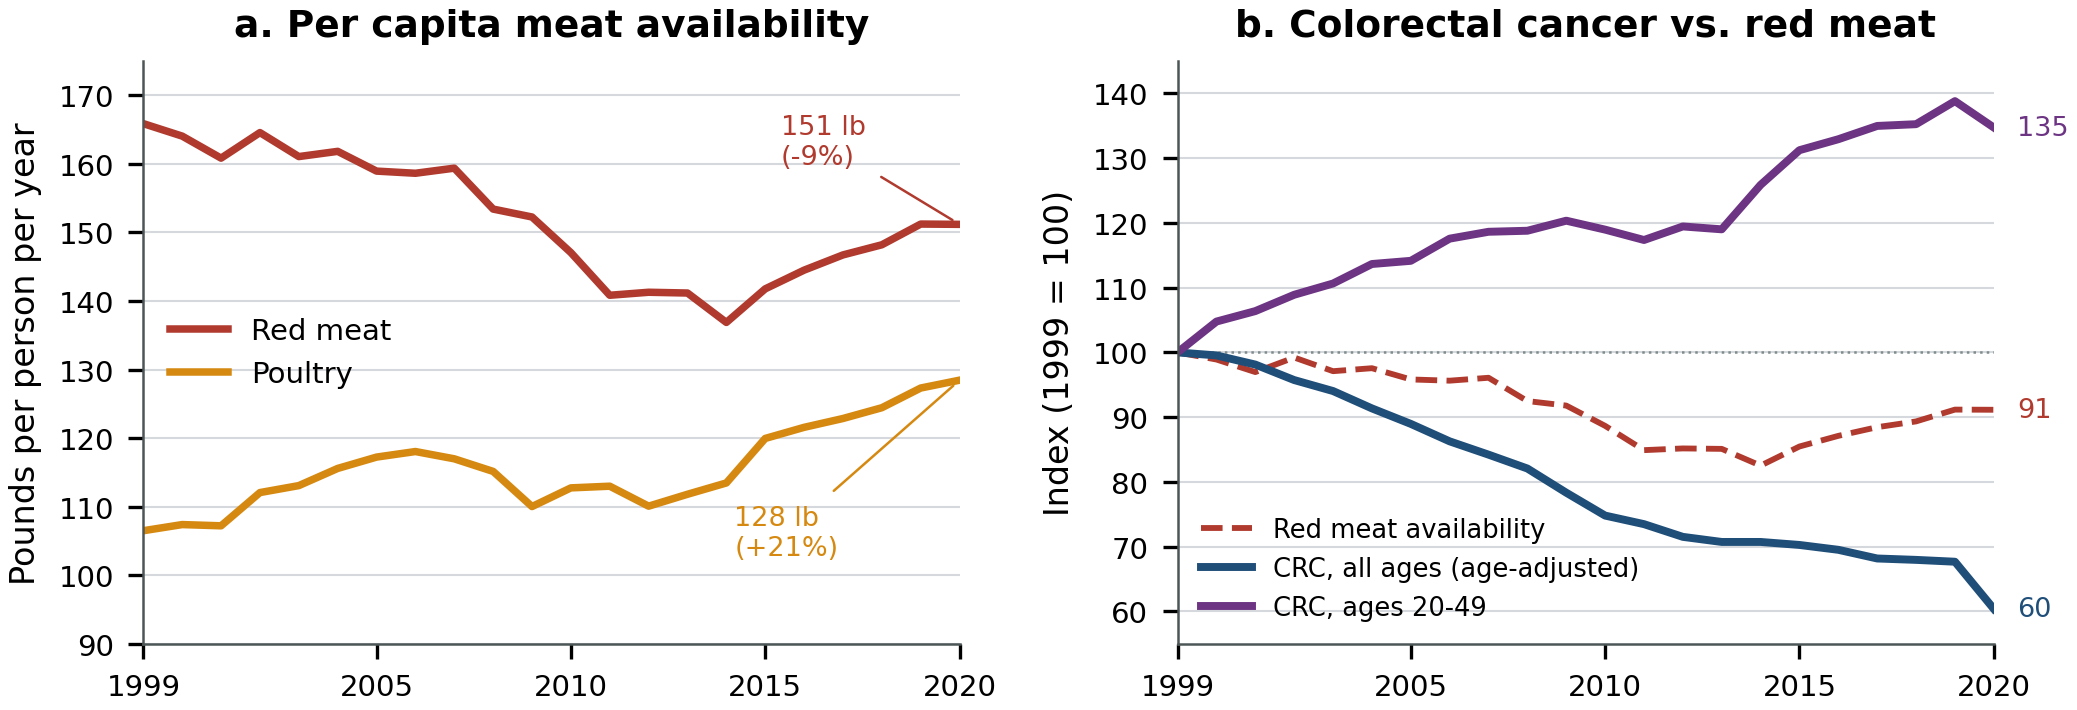

In [6]:
fig = fig1_national_trends(panel, nat, meat)
display(Image(filename=fig, width=950))

**Figure 1.** (a) Per capita red meat and poultry availability, 1999–2020. (b) CRC incidence and red meat availability indexed to 1999 = 100. Overall CRC falls much faster than red meat, while early-onset CRC moves in the opposite direction.

## 2. Age matters more than anything else

CRC is overwhelmingly a disease of older adults, but the age-specific trends diverge. The 65+ rate fell 55%, the 50–64 rate fell 23%, and the 20–49 rate rose 35%. A single all-ages rate hides the only segment that is getting worse.

In [7]:
age.pivot(index="year", columns="age_band", values="crc_crude_rate").loc[[1999, 2010, 2020]].round(2)

age_band,20-49,50-64,65+
year,,,
1999,9.56,85.33,307.02
2010,11.38,71.21,206.93
2020,12.88,65.44,137.47


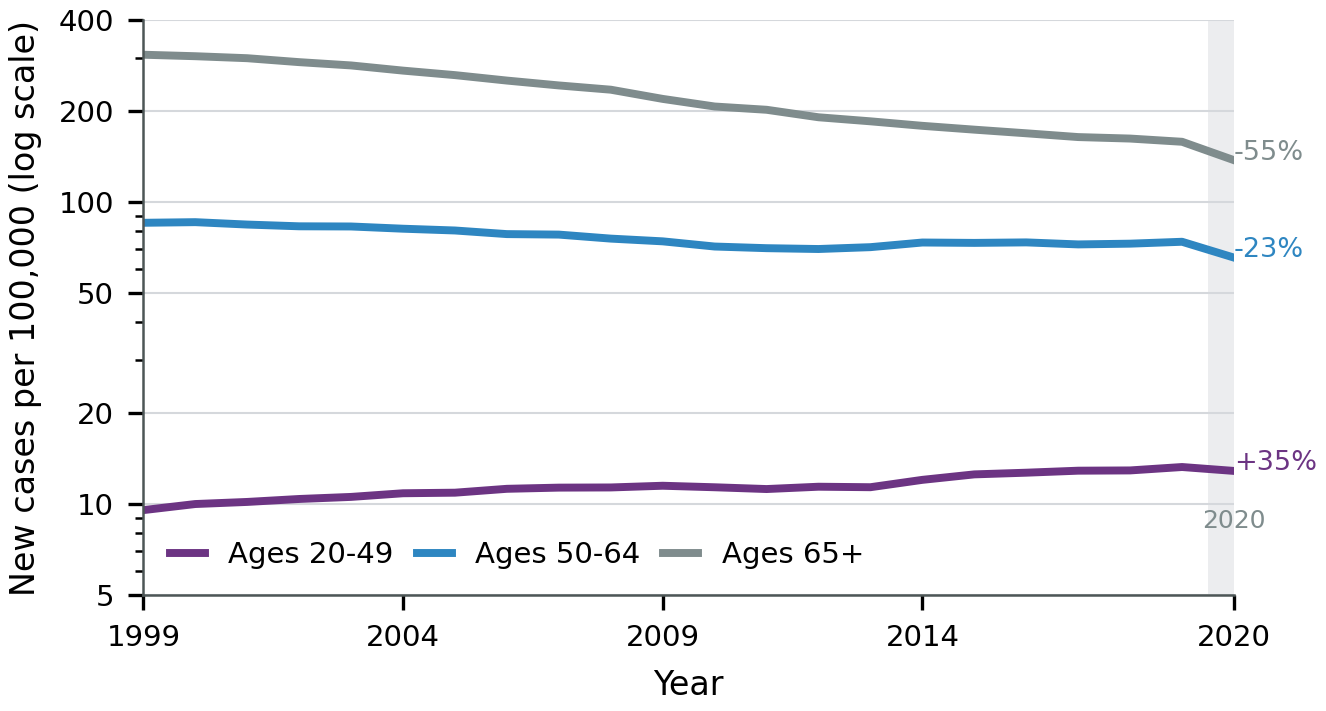

In [8]:
fig = fig2_age_specific(age)
display(Image(filename=fig, width=650))

**Figure 2.** CRC incidence by age band, 1999–2020 (log scale). The shaded 2020 bar marks pandemic-related disruption; the 2020 point should not be read as a new trend.

## 3. Geography: where early-onset CRC rose fastest

State changes are measured as the difference between each state's first and last observed early-onset rate (typically 1999 and 2020). The average state increase was about +3.6 per 100,000, but the range is wide: Wyoming, South Dakota, and New Hampshire increased by more than 7 per 100,000, while Vermont, Mississippi, and Delaware were flat or fell.

In [9]:
state_change = (panel.sort_values("year")
    .groupby("state_abbr")
    .agg(first_year=("year", "first"), last_year=("year", "last"),
         early_first=("crc_early_rate", "first"), early_last=("crc_early_rate", "last"),
         region=("region", "first"))
    .dropna())
state_change["change"] = state_change.early_last - state_change.early_first
state_change.sort_values("change", ascending=False).head(10).round(2)

,first_year,last_year,early_first,early_last,region,change
state_abbr,,,,,,
WY,1999,2020,7.57,15.94,West,8.37
SD,2001,2020,6.41,14.69,Midwest,8.28
NH,1999,2020,7.88,15.35,Northeast,7.47
ID,1999,2020,7.03,13.65,West,6.62
UT,1999,2020,5.69,12.22,West,6.53
MT,1999,2020,8.76,14.27,West,5.51
MD,1999,2020,9.06,14.56,South,5.50
WV,1999,2020,11.47,16.86,South,5.39
HI,1999,2020,10.39,15.63,West,5.24


In [10]:
state_change.sort_values("change").head(6).round(2)

,first_year,last_year,early_first,early_last,region,change
state_abbr,,,,,,
VT,1999,2020,11.32,8.51,Northeast,-2.81
MS,2003,2020,13.87,13.58,South,-0.29
DE,1999,2020,11.72,11.68,South,-0.04
ND,1999,2020,9.11,9.57,Midwest,0.46
RI,1999,2020,9.86,10.56,Northeast,0.70
KS,1999,2020,11.74,12.84,Midwest,1.10


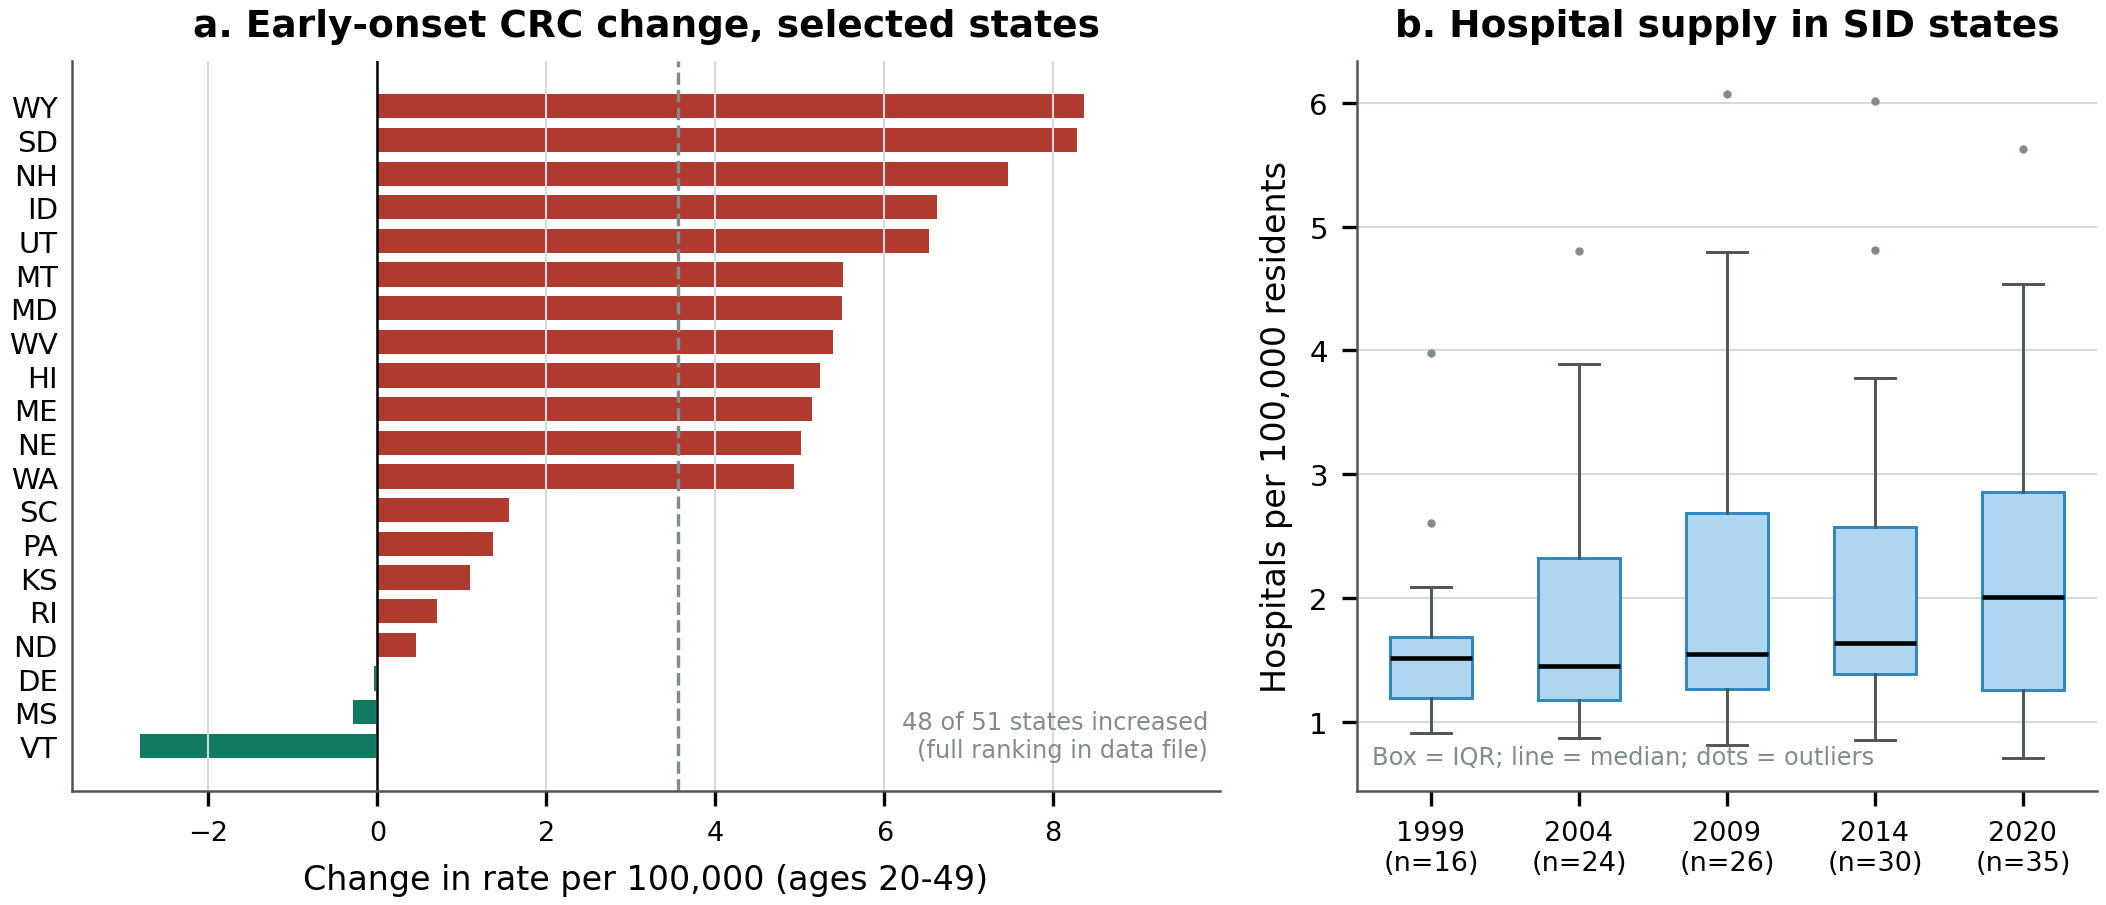

In [11]:
fig = fig3_states_hospitals(panel)
display(Image(filename=fig, width=950))

**Figure 3.** (a) Change in early-onset CRC rate by state, first to last observed year. (b) Distribution of hospitals per 100,000 residents among SID-reporting states. The dashed line in (a) is the unweighted mean state change.

## 4. Hospital supply: flat per capita, wide variation

The number of SID hospitals per 100,000 residents is essentially flat within states: the median within-state change from first to last observation is about −5%, and the median level moves only because the set of reporting states changes over time. Hospital density is not a plausible explanation for the geographic pattern in early-onset CRC.

In [12]:
hosp = panel.dropna(subset=["hospitals_per100k"])
print("State-years with hospital data:", len(hosp), "| states:", hosp.state_abbr.nunique())
hosp.groupby("year").hospitals_per100k.agg(["median", "count"]).round(2).T

State-years with hospital data: 583 | states: 36


year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
median,1.51,1.51,1.49,1.47,1.47,1.45,1.54,1.5,1.5,1.57,1.55,1.55,1.8,1.67,1.64,1.64,1.82,1.89,2.05,1.99,2.05,2.01
count,16.00,19.00,21.00,22.00,23.00,24.00,24.00,25.0,25.0,26.00,26.00,26.00,29.0,27.00,26.00,30.00,30.00,31.00,31.00,33.00,34.00,35.00


In [13]:
by_state = (hosp.sort_values("year").groupby("state_abbr")
    .agg(first_year=("year", "first"), last_year=("year", "last"),
         h_first=("hospitals_per100k", "first"), h_last=("hospitals_per100k", "last"),
         crc_change=("crc_age_adj_rate", lambda s: s.iloc[-1] - s.iloc[0]),
         early_change=("crc_early_rate", lambda s: s.iloc[-1] - s.iloc[0])))
by_state["hospital_change_pct"] = by_state.h_last / by_state.h_first - 1
print("Median within-state change in hospitals per 100k:", round(by_state.hospital_change_pct.median(), 3))
print("Correlation with overall CRC change:", round(by_state.hospital_change_pct.corr(by_state.crc_change), 3))
print("Correlation with early-onset CRC change:", round(by_state.hospital_change_pct.corr(by_state.early_change), 3))
by_state[["h_first", "h_last", "hospital_change_pct", "crc_change", "early_change"]].round(2).head()

Median within-state change in hospitals per 100k: -0.051
Correlation with overall CRC change: -0.129
Correlation with early-onset CRC change: 0.241


,h_first,h_last,hospital_change_pct,crc_change,early_change
state_abbr,,,,,
AK,4.58,3.27,-0.29,-2.88,-3.27
AR,3.75,3.45,-0.08,-12.82,2.44
AZ,1.19,1.71,0.43,-16.30,3.69
CA,1.29,1.12,-0.13,-19.55,4.00
CO,1.63,1.54,-0.06,-18.39,4.01


## 5. Correlation caution

The table below shows Pearson correlations between national series in levels and in first differences. The level correlations are large and misleading; the first-difference correlations are small. We therefore do not interpret the national meat–CRC correlation as causal.

In [14]:
corr = summary[["crc_age_adj_rate", "crc_early_rate", "red_meat_lb_pc", "poultry_lb_pc"]]
print("Levels")
display(corr.corr().round(3))
print("First differences")
display(corr.diff().dropna().corr().round(3))

Levels


,crc_age_adj_rate,crc_early_rate,red_meat_lb_pc,poultry_lb_pc
crc_age_adj_rate,1.000,-0.908,0.853,-0.678
crc_early_rate,-0.908,1.000,-0.656,0.869
red_meat_lb_pc,0.853,-0.656,1.000,-0.282
poultry_lb_pc,-0.678,0.869,-0.282,1.000


First differences


,crc_age_adj_rate,crc_early_rate,red_meat_lb_pc,poultry_lb_pc
crc_age_adj_rate,1.000,0.623,0.129,0.237
crc_early_rate,0.623,1.000,0.293,0.243
red_meat_lb_pc,0.129,0.293,1.000,0.423
poultry_lb_pc,0.237,0.243,0.423,1.000


### Key EDA takeaways

1. **Overall CRC incidence fell by 40%** between 1999 and 2020, consistent with screening and polyp removal.
2. **Early-onset CRC (20–49) rose by 35%**, and every state except a handful saw an increase.
3. **Red meat availability fell 9%** and poultry rose 21%; national meat trends do not track the early-onset increase.
4. **Hospital supply per capita was roughly flat** and is weakly related to CRC changes.
5. Simple level correlations are dominated by shared time trends; the report relies on age stratification, state variation, and a multivariable model instead.
